# t-SNE

t-SNE emphasises local neighbours. The distance between two well-separated islands has no simple global interpretation.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Pixels and estimator

Pixel intensities are rescaled to the unit interval. Digit labels stratify the sample, colour the plot and score neighbour agreement. The embedding is fitted using only pixel values.

In [2]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from gallery.unsupervised import digit_sample, embedding_report

## Two coordinates

The same stratified sample of 650 images is used across the embedding examples.

In [3]:
X, y = digit_sample()
model = TSNE(
    n_components=2, perplexity=27, init="pca", learning_rate="auto", max_iter=800, random_state=17
)
Z = model.fit_transform(X)

## Neighbour preservation

Neighbour overlap compares the ten nearest points before and after projection.

Trustworthiness at 10: 0.985
Mean neighbour overlap at 10: 0.644
Neighbour label agreement (evaluation only): 0.938
Final KL divergence: 0.564


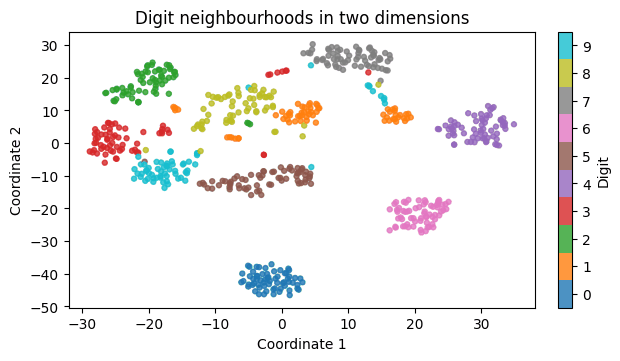

In [4]:
embedding_report(model, X, y, Z)
plt.show()

## Reading the result

These are descriptive scores on the fitted sample. Colour mixing identifies different digits whose projected neighbourhoods overlap.

## References

[scikit-learn, TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Dataset generators and evaluation](../../../gallery/unsupervised.py)